# 07 — Historical Stress Testing

Two lenses on the fixed windows in `data/metadata/stress_periods.csv` (dates frozen before running):

| Lens | Question | Method |
|---|---|---|
| **A. Scenario replay** | What would each past crisis do to **today's** portfolios? | Buy-and-hold the September 2026 target weights through the window, using the daily EUR asset returns of that window. Exact P&L decomposition: $R=\sum_i L\,w_i\big(\prod(1+r_i)-1\big)+(1-L\sum_i w_i)\big(\prod(1+r^{cash})-1\big)$. |
| **B. Realised out-of-sample** | What did the strategies actually do? | Net daily returns from notebook 05, only for windows after the first OOS date (2010-04-30). |

Lens A can include the **GFC** (all 12 assets exist from 2007-04), which lens B cannot (in-sample). The dot-com window lacks most assets and is skipped.

**Pre-registered expectations:** (1) hedged government bonds offset equity losses in the GFC and COVID but add to losses in 2022; (2) the levered risk-parity portfolio is the most fragile in 2022 and the most robust in the GFC; (3) replacing AAA by all-issuer euro bonds worsens the euro-crisis outcome.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import backtest as B, data_loader as dl, optimize as O, risk as K, stress as St, universe as U

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
PROC = ROOT / "data" / "processed"
daily = pd.read_csv(PROC / "asset_returns_eur_daily.csv", index_col="date", parse_dates=True)
weekly = pd.read_csv(PROC / "asset_returns_eur_weekly.csv", index_col="date", parse_dates=True)
nets = pd.read_csv(PROC / "backtest_daily_net.csv", index_col=0, parse_dates=True)      # notebook 05
fc = K.load_forecasts(PROC / "cov_forecasts.npz")
paths = O.weight_paths(fc, weekly[U.ASSETS].dropna(), cache_dir=PROC / "weights")
cash = B.daily_cash_returns(daily.index, dl.load_short_rates()["EUR"])
periods = dl.load_stress_periods()
T_NOW = fc["dates"][-1]
lev_rp = B.vol_target_leverage(paths["RiskParity"], fc["cov1w"]["GARCH-CCC"], paths["60/40"])
STRATS = {m: (paths[m].loc[T_NOW], 1.0) for m in ["EW", "60/40", "MinVar", "RiskParity", "CVaR"]}
STRATS["RiskParity*"] = (paths["RiskParity"].loc[T_NOW], float(lev_rp.loc[T_NOW]))
FIRST_OOS = pd.Timestamp("2010-04-30")
print(f"current portfolios = targets decided {T_NOW:%Y-%m-%d}; RiskParity* leverage {STRATS['RiskParity*'][1]:.2f}x")

current portfolios = targets decided 2026-08-31; RiskParity* leverage 3.62x


## 1. Windows and data availability

In [2]:
rows = []
for _, s in periods.iterrows():
    miss = [a for a in U.ASSETS if a not in St.available(daily, U.ASSETS, s.start_date)]
    rows.append({"id": s.stress_id, "window": f"{s.start_date:%Y-%m-%d} → {s.end_date:%Y-%m-%d}",
                 "replay (A)": "yes" if not miss else f"no: {len(miss)} assets missing",
                 "realised OOS (B)": "yes" if s.start_date >= FIRST_OOS else ("partial" if s.end_date > FIRST_OOS else "no (in-sample)"),
                 "description": s.description})
avail = pd.DataFrame(rows).set_index("id")
avail

,window,replay (A),realised OOS (B),description
id,,,,
DOTCOM,2000-03-24 → 2002-10-09,no: 9 assets missing,no (in-sample),S&P 500 peak to trough
GFC,2007-10-09 → 2009-03-09,yes,no (in-sample),S&P 500 peak to trough; before first out-of-sa...
EURO,2010-04-01 → 2012-07-26,yes,partial,Ends at Draghi 'whatever it takes'
TAPER,2013-05-22 → 2013-09-05,yes,yes,Bernanke taper remarks to 10Y peak
CHINA,2015-08-10 → 2016-02-11,yes,yes,CNY devaluation to equity trough
Q4_2018,2018-10-01 → 2018-12-24,yes,yes,Fed tightening sell-off
COVID,2020-02-19 → 2020-03-23,yes,yes,S&P 500 peak to trough
RATES22,2022-01-03 → 2022-10-12,yes,yes,Stock-bond correlation turns positive
BANK23,2023-03-08 → 2023-03-31,yes,yes,SVB / Credit Suisse


## 2. Lens A — replay of today's portfolios

In [3]:
replays, table, dd = {}, {}, {}
for _, s in periods.iterrows():
    if avail.loc[s.stress_id, "replay (A)"] != "yes":
        continue
    for k, (w, lev) in STRATS.items():
        r = St.replay(w, daily[U.ASSETS], s.start_date, s.end_date, cash, lev)
        replays[(s.stress_id, k)] = r
        table[(s.stress_id, k)] = r.cum_return * 100
        dd[(s.stress_id, k)] = r.max_drawdown * 100
order = [i for i in periods.stress_id if i in {w for w, _ in table}]          # chronological
cum = pd.Series(table).unstack().loc[order, list(STRATS)]
mdd = pd.Series(dd).unstack().loc[order, list(STRATS)]
pd.concat({"cumulative return %": cum, "max drawdown %": mdd}, axis=1)

cumulative return %                ... max drawdown %                  
                         EW  60/40 MinVar  ...     RiskParity  CVaR RiskParity*
GFC                   -7.32 -24.37   0.24  ...          -3.89 -7.61      -16.68
EURO                  24.85  23.61  13.81  ...          -1.51 -2.51       -5.00
TAPER                 -3.59  -3.02  -1.29  ...          -2.66 -2.30       -9.67
CHINA                 -5.35  -8.76  -1.28  ...          -2.01 -3.17       -7.13
Q4_2018               -4.93  -9.53  -1.33  ...          -1.49 -2.20       -5.15
COVID                -11.29 -19.04  -5.41  ...          -5.22 -7.15      -18.68
RATES22               -8.99 -14.60  -8.07  ...          -8.96 -6.51      -31.60
BANK23                 1.81   1.11   2.03  ...          -0.60 -0.31       -2.15

[8 rows x 12 columns]

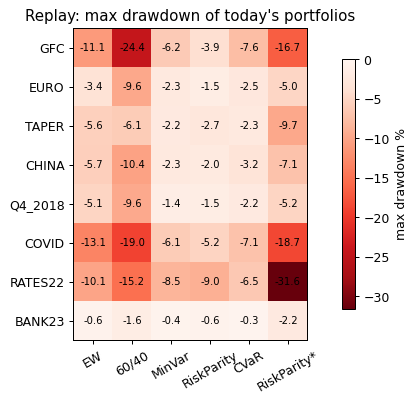

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(mdd.values, cmap="Reds_r", vmin=mdd.values.min(), vmax=0)
ax.set_xticks(range(mdd.shape[1]), mdd.columns, rotation=30); ax.set_yticks(range(mdd.shape[0]), mdd.index)
for i in range(mdd.shape[0]):
    for j in range(mdd.shape[1]):
        ax.text(j, i, f"{mdd.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="max drawdown %"); ax.set_title("Replay: max drawdown of today's portfolios"); plt.show()

### Where do the losses come from? (sleeve contributions, % of capital)

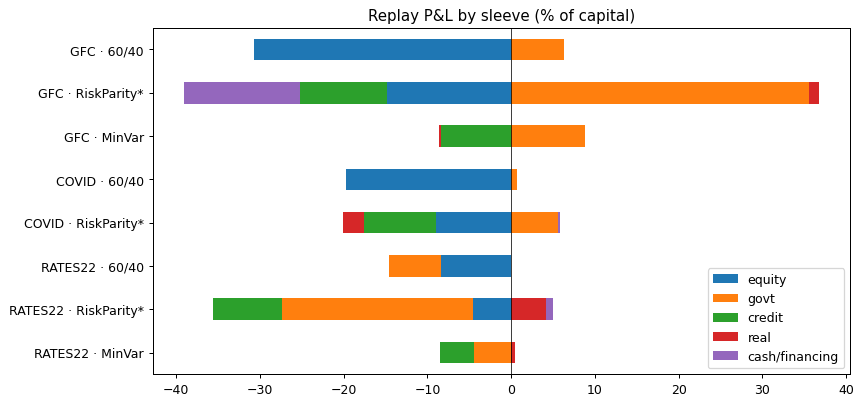

,equity,govt,credit,real,cash/financing,total
GFC · 60/40,-30.74,6.37,0.00,0.00,0.00,-24.37
GFC · RiskParity*,-14.81,35.62,-10.40,1.10,-13.81,-2.30
GFC · MinVar,0.00,8.86,-8.42,-0.21,0.00,0.24
COVID · 60/40,-19.73,0.69,0.00,0.00,-0.00,-19.04
COVID · RiskParity*,-8.99,5.66,-8.60,-2.46,0.13,-14.26
RATES22 · 60/40,-8.39,-6.22,0.00,0.00,-0.00,-14.60
RATES22 · RiskParity*,-4.58,-22.83,-8.21,4.19,0.76,-30.67
RATES22 · MinVar,0.00,-4.38,-4.14,0.45,-0.00,-8.07


In [5]:
def sleeve_contrib(r):
    c = r.contributions
    s = c.drop("cash/financing").groupby(pd.Series(U.SLEEVE)).sum()
    s["cash/financing"] = c["cash/financing"]
    return s * 100
sel = [("GFC", k) for k in ["60/40", "RiskParity*", "MinVar"]] + [("COVID", k) for k in ["60/40", "RiskParity*"]] + \
      [("RATES22", k) for k in ["60/40", "RiskParity*", "MinVar"]]
contrib = pd.DataFrame({f"{w} · {k}": sleeve_contrib(replays[(w, k)]) for w, k in sel}).T[["equity", "govt", "credit", "real", "cash/financing"]]
ax = contrib.plot.barh(stacked=True, figsize=(10, 5), title="Replay P&L by sleeve (% of capital)")
ax.axvline(0, color="k", lw=0.6); ax.invert_yaxis(); plt.show()
contrib.assign(total=contrib.sum(axis=1))

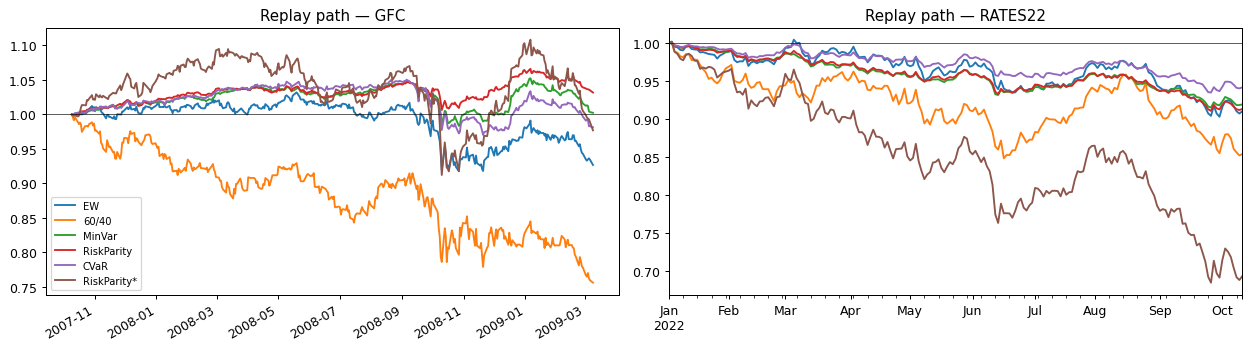

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, wid in zip(axes, ["GFC", "RATES22"]):
    for k in STRATS:
        replays[(wid, k)].path.plot(ax=ax, label=k)
    ax.set_title(f"Replay path — {wid}"); ax.axhline(1, color="k", lw=0.5)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Euro sovereign crisis: AAA core vs all-issuer bonds

The investable euro bond is built on the AAA curve, which **rallied** in the crisis (flight to quality). Replacing it by the all-issuer synthetic bond shows the loss a portfolio holding periphery debt would have taken. Also shown: Jul–Nov 2011, the acute phase.

In [7]:
sub = {}
for wid, (a, b) in {"EURO window": ("2010-04-01", "2012-07-26"), "acute 2011-07 … 2011-11": ("2011-07-01", "2011-11-30")}.items():
    for k in ["EW", "60/40", "MinVar", "RiskParity", "RiskParity*"]:
        w, lev = STRATS[k]
        w_all = w.copy(); w_all["EUR_ALL7_10_SYN"] = w_all.pop("EUR_CORE7_10_SYN")
        core = St.replay(w, daily[U.ASSETS], a, b, cash, lev)
        alli = St.replay(w_all, daily[w_all.index], a, b, cash, lev)
        sub[(wid, k)] = {"EUR weight %": 100 * w["EUR_CORE7_10_SYN"] * lev, "AAA core %": 100 * core.cum_return,
                         "all-issuer %": 100 * alli.cum_return, "difference %": 100 * (alli.cum_return - core.cum_return)}
pd.DataFrame(sub).T

EUR weight %  ...  difference %
EURO window             EW                   8.33  ...         -0.85
                        60/40               20.00  ...         -2.05
                        MinVar               5.43  ...         -0.56
                        RiskParity           7.56  ...         -0.77
                        RiskParity*         27.40  ...         -2.81
acute 2011-07 … 2011-11 EW                   8.33  ...         -0.52
                        60/40               20.00  ...         -1.26
                        MinVar               5.43  ...         -0.34
                        RiskParity           7.56  ...         -0.47
                        RiskParity*         27.40  ...         -1.72

[10 rows x 4 columns]

In [8]:
eurusd = dl.load_fx()["EURUSD"]
print(f"EURUSD {eurusd.asof(pd.Timestamp('2010-04-01')):.3f} → {eurusd.asof(pd.Timestamp('2012-07-26')):.3f}: "
      f"a weaker euro lifted unhedged USD assets for a EUR investor during the euro crisis")

EURUSD 1.357 → 1.228: a weaker euro lifted unhedged USD assets for a EUR investor during the euro crisis


## 4. Lens B — realised out-of-sample performance in the windows

In [9]:
real = {}
for _, s in periods.iterrows():
    if s.end_date <= FIRST_OOS:
        continue
    a = max(s.start_date, FIRST_OOS)
    for k in ["EW", "60/40", "MinVar", "RiskParity", "CVaR", "RiskParity*"]:
        st = St.realised(nets[k], a, s.end_date)
        real[(s.stress_id + (" (from 2010-04-30)" if a > s.start_date else ""), k)] = st
realised_tab = pd.DataFrame(real).T
real_order = list(dict.fromkeys(i for i, _ in real))
(realised_tab["cum. return"] * 100).unstack().loc[real_order, ["EW", "60/40", "MinVar", "RiskParity", "CVaR", "RiskParity*"]]

,EW,60/40,MinVar,RiskParity,CVaR,RiskParity*
EURO (from 2010-04-30),22.93,22.41,10.79,12.21,10.53,62.09
TAPER,-3.56,-3.03,-1.51,-1.33,-2.26,-6.86
CHINA,-5.78,-9.01,0.56,-0.07,-1.59,-0.11
Q4_2018,-5.14,-9.71,-0.44,-0.89,0.13,-3.29
COVID,-12.02,-20.12,-4.11,-4.28,-4.47,-19.73
RATES22,-10.04,-14.52,-8.77,-7.74,-7.94,-28.69
BANK23,1.80,1.09,1.72,1.84,2.37,4.53


In [10]:
comp = pd.DataFrame({"replay (today's weights)": cum["RiskParity*"], "realised (weights at the time)":
                     (realised_tab["cum. return"].unstack()["RiskParity*"] * 100).rename(lambda x: x.split(" ")[0])}).dropna().loc[[i for i in order if i in cum.index and i != "GFC"]]
comp

,replay (today's weights),realised (weights at the time)
EURO,50.59,62.09
TAPER,-7.26,-6.86
CHINA,-4.00,-0.11
Q4_2018,-4.80,-3.29
COVID,-14.26,-19.73
RATES22,-30.67,-28.69
BANK23,7.02,4.53


## 5. Stock–bond correlation inside each window

Weekly EUR returns (bonds hedged). Short windows have few observations — read signs, not decimals.

In [11]:
corr_rows = {}
for _, s in periods.iterrows():
    w = weekly.loc[s.start_date:s.end_date]
    if w[["SPY", "IEF", "EUR_CORE7_10_SYN"]].dropna().shape[0] < 4:
        continue
    corr_rows[s.stress_id] = {"weeks": len(w), "SPY–IEF": w.SPY.corr(w.IEF), "SPY–EUR core": w.SPY.corr(w.EUR_CORE7_10_SYN),
                              "SPY–GLD": w.SPY.corr(w.GLD), "SPY–HYG": w.SPY.corr(w.HYG)}
ws = weekly.loc["2007-04-18":]
corr_rows["full sample"] = {"weeks": len(ws), "SPY–IEF": ws.SPY.corr(ws.IEF), "SPY–EUR core": ws.SPY.corr(ws.EUR_CORE7_10_SYN),
                            "SPY–GLD": ws.SPY.corr(ws.GLD), "SPY–HYG": ws.SPY.corr(ws.HYG)}
pd.DataFrame(corr_rows).T

,weeks,SPY–IEF,SPY–EUR core,SPY–GLD,SPY–HYG
GFC,74.00,-0.22,-0.15,-0.17,0.45
EURO,121.00,-0.54,-0.16,0.14,0.66
TAPER,16.00,-0.15,0.13,-0.08,0.51
CHINA,27.00,-0.44,0.07,0.24,0.60
Q4_2018,12.00,-0.67,0.08,0.20,0.83
COVID,5.00,0.40,0.19,0.54,0.74
RATES22,41.00,0.18,0.26,0.04,0.68
BANK23,4.00,-0.78,-0.40,-0.80,0.19
full sample,1016.00,-0.20,-0.01,0.07,0.54


In [12]:
out = PROC / "stress"; out.mkdir(exist_ok=True)
pd.concat({"cum_return_pct": cum, "max_drawdown_pct": mdd}, axis=1).to_csv(out / "replay_summary.csv")
contrib.to_csv(out / "replay_sleeve_contributions.csv")
realised_tab.to_csv(out / "realised_windows.csv")
sorted(p.name for p in out.glob("*.csv"))

['realised_windows.csv', 'replay_sleeve_contributions.csv', 'replay_summary.csv']

## Expectations — verdict and takeaways

| # | Expectation | Verdict |
|---|---|---|
| 1 | Hedged government bonds offset equity losses in the GFC and COVID, add to them in 2022 | **Confirmed, weaker in COVID.** Government-bond sleeve in the replay: GFC +6.4% (60/40) / +35.6% (RP\*); COVID only +0.7% / +5.7% — in the March 2020 dash for cash SPY–IEF correlation was +0.40 over those 5 weeks; 2022 −6.2% / −22.8%. |
| 2 | Levered risk parity most robust in the GFC, most fragile in 2022 | **Confirmed.** GFC replay: RP\* −2.3% vs 60/40 −24.4%. 2022: RP\* −30.7% (realised −28.7%) vs 60/40 −14.6%. The same leverage that saved it in 2008 sank it in 2022. |
| 3 | All-issuer euro bonds worsen the euro crisis | **Confirmed but small:** −0.6 to −2.8 pp over the window, −0.3 to −1.7 pp in Jul–Nov 2011, because euro bonds are only 5–27% of capital. |

* **The euro crisis was a gain for a EUR investor** (+14% to +51% over the window): EURUSD fell from 1.357 to 1.228, so unhedged USD equity, gold and commodities rose in euros. The sovereign stress shows up only in the AAA-vs-all comparison.
* **60/40 is an equity-crash portfolio**, losing 8.8–24.4% in every equity sell-off (China 2015, Q4 2018, COVID, GFC); the unlevered risk-based portfolios lose at most 7.1% there and gain slightly in the GFC. In 2022 every rule lost; the best was CVaR (−5.9% replay, −7.9% realised) because its tail scenarios already contained rate shocks.
* **Leverage costs carry, not only risk.** In the GFC replay RP\*'s 3.6× leverage paid −13.8% of capital in EUR financing at 2007–08 rates; in 2022 near-zero rates made financing almost free while bond losses were large.
* **Replay and realised agree on direction** for RP\* in all seven OOS windows; magnitudes differ most in China 2015 (−4.0% vs −0.1%) and COVID (−14.3% vs −19.7%: the strategy's leverage was raised to the 5× cap at the end-February 2020 rebalance, vs 3.6× today). Today's portfolios carry crisis exposures similar to those traded at the time.
* **Stress tests complement VaR.** Notebook 06's best model (FHS) gave a 99% one-day VaR of ~1.5% for 60/40; the replay shows −19% over five weeks in COVID and −24% over 17 months in the GFC — horizon and path matter as much as the daily tail.

Next: notebook 08 — results summary across notebooks 02–07.